In [12]:
# ============================================================
# 1. STANDARD LIBRARY
# ============================================================
import argparse
import gc
import os
import sys
import time
from datetime import datetime

# ============================================================
# 2. THIRD-PARTY LIBRARIES
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sourcedefender
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from IPython.display import clear_output, display
from matplotlib.ticker import ScalarFormatter
from mpl_toolkits.mplot3d import Axes3D
from torch.utils.data import (
    DataLoader,
    Subset,
    TensorDataset,
    dataset,
    random_split,
)
from tqdm import tqdm

# ============================================================
# 3. PROJECT PATHS
# ============================================================
sys.path.extend([
    "../../../",
    "../",
    "./",
])

# ============================================================
# 4. PROJECT UTILITIES
# ============================================================
from lib.util import (
    MHPI,
    UnitGaussianNormalizer,
)

from lib.utilities3 import (
    NonLocalMeansSmoothing,
    adjust_state_dict,
    calculate_errors,
    calculate_relative_errors,
    check_if_from_ddp,
    plot_log_loss,
    prepare_dataset,
    upscale_tensor,
)

from lib.utiltools import (
    AutomaticWeightedLoss,
    GaussianRandomFieldGenerator,
    generate_batch_parameters,
    loss_live_plot,
)

from lib.DerivativeComputer import batchJacobian_AD_Dist

# ============================================================
# 5. DATASET AND HELPER FUNCTIONS
# ============================================================
from lib.helper import (
    LargeHydrologyDataset,
    get_checkpoint_path,
)

from lib.hellper import *

# ============================================================
# 6. EVALUATION AND VISUALIZATION
# ============================================================
from lib.evaluation import (
    evaluate_flood_metrics,
    eventwise_csi_for_violin,
    eventwise_relrmse_nse_for_violin,
    inundation_extent_timeseries,
    plot_detection_skill_time,
    plot_ever_inundation_confusion,
    plot_inundation_extent_time,
    plot_metrics,
    plot_test_violin,
    plot_test_violin_D,
)

In [13]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'Device: {device}\n')

# Dataset and case configuration
SAVED_MODEL_PATH = '../../../experiments/dam_break/saved_models'
# This creates a 'pointer' to the data on disk without filling up your RAM
case = 'dam_break'
operator_type = 'FNO'

eval_size = 150
batch_size = 8
T_Total = 49
# DRY_THRESHOLD = 0.025 

T_in = 1
T_out = T_Total - T_in

Nx = 164 * 2
Ny = 164

Device: cuda:0



# Loading Checkpoint

In [14]:
# --- 1. Load Magnifier Model ---
train_size = 300

mode_mag = 'test_mag_residual_model5_Deeper_stage2_N1'
path_mag = '../../../experiments/saved_model/dam_break_model.pth'

checkpoint_mag = torch.load(path_mag, map_location=device, weights_only=False)

if 'stage1' in mode_mag:
    plot_log_loss(checkpoint_mag["loss_df_main"], mode=mode_mag + '_Global_Model' + f'  (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)
else:
    plot_log_loss(checkpoint_mag["loss_df_magnifier"], mode=mode_mag + '_Magnifier_Model' + f' (Epoch: {checkpoint_mag["epoch"]})', plot_ig_loss=False)


# Loading Dataset

In [15]:
config = checkpoint_mag.get('config_arg')
if isinstance(config, dict):
    experiment = config.get('experiment')
    if isinstance(experiment, dict):
        UQ_mode = experiment.get('UQ_mode', False)
    else:
        UQ_mode = False
else:
    UQ_mode = False



from pathlib import Path

data_dir = Path("../../../datasets/2_dam_break")

topo_path = data_dir / "dam_break_bed_topo.pt"
a_path    = data_dir / "dam_break_input.pt"
u_path    = data_dir / "dam_break_solution.pt"


if not UQ_mode:
    full_dataset = LargeHydrologyDataset(a_path, u_path, mask=True, 
                                        csv_path=os.path.join('../../../',  checkpoint_mag['config_arg']['data_mask']['csv_path']), 
                                        Lx=checkpoint_mag['config_arg']['data_mask']['L_x'], Ly=checkpoint_mag['config_arg']['data_mask']['L_y'])

    topo = torch.load(topo_path, map_location="cpu").to(device)  # ---- Static topo ---
    GLOBAL_TOPO_MIN = topo.min()
    GLOBAL_TOPO_MAX = topo.max()
    TOPO_RANGE = GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN + 1e-7

else:
    full_dataset = LargeHydrologyDataset(a_path, u_path, topo_path, mask=True, 
                                        csv_path=os.path.join('../../../',  checkpoint_mag['config_arg']['data_mask']['csv_path']), 
                                        Lx=checkpoint_mag['config_arg']['data_mask']['L_x'], Ly=checkpoint_mag['config_arg']['data_mask']['L_y'])

    GLOBAL_TOPO_MIN = full_dataset.b.min()
    GLOBAL_TOPO_MAX = full_dataset.b.max()
    TOPO_RANGE = GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN + 1e-7
    GLOBAL_TOPO_MEAN = full_dataset.b.mean(dim=(0, 1, 2))
    GLOBAL_TOPO_STD  = full_dataset.b.std(dim=(0, 1, 2)) + 1e-6


# 2. Split with a fixed generator for reproducibility
n = len(full_dataset)

# Make deterministic indices
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n, generator=g).tolist()
test_idx  = perm[train_size + eval_size:]
test_dataset = Subset(full_dataset, test_idx)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Loading Trained Models

In [16]:
from models.fno3d_encoder import FNO3d
from models.magnifier5 import FiLMLightMagnifier as Magnifier

# ============================================================
# 1. LOAD GLOBAL FNO MODEL
# ============================================================

model_global = FNO3d(
    T_in=T_in,
    T_out=T_out,
    modes_x=checkpoint_mag["config"]["Mode1_G"],
    modes_y=checkpoint_mag["config"]["Mode2_G"],
    modes_t=checkpoint_mag["config"]["Mode3_G"],
    width=checkpoint_mag["config"]["width_FNO"],
    encoder_kernel_size_x=82,
    encoder_kernel_size_y=41,
    encoder_num_layers=4,
)

# Load global model weights
state_dict_global = checkpoint_mag["model_state_dict"]

if check_if_from_ddp(checkpoint_mag):
    state_dict_global = adjust_state_dict(state_dict_global, model_global)

model_global.load_state_dict(state_dict_global)
model_global = model_global.to(device)
model_global.eval()

# ============================================================
# 2. LOAD MAGNIFIER MODEL
# ============================================================

tag_mag_stage2 = "test_mag_residual_model5_Deeper_stage2_N1"
path_mag_2 = "../../../experiments/saved_model/dam_break_best_model.pth"

checkpoint_mag_stage2 = torch.load(
    path_mag_2,
    map_location=device,
    weights_only=False,
)

# Initialize magnifier
model_magnifier = Magnifier(width=64)

# Load magnifier weights
state_dict_mag = checkpoint_mag_stage2["magnifier_state_dict"]

if check_if_from_ddp(checkpoint_mag_stage2):
    state_dict_mag = adjust_state_dict(state_dict_mag, model_magnifier)

model_magnifier.load_state_dict(state_dict_mag)
model_magnifier = model_magnifier.to(device)
model_magnifier.eval()

FiLMLightMagnifier(
  (cond_extractor): Sequential(
    (0): Conv3d(2, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): GELU(approximate='none')
  )
  (base_extractor): Sequential(
    (0): Conv3d(1, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): GELU(approximate='none')
  )
  (film): FiLMLayer(
    (norm): InstanceNorm3d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
    (gen_gamma): Conv3d(64, 64, kernel_size=(1, 1, 1), stride=(1, 1, 1))
    (gen_beta): Conv3d(64, 64, kernel_size=(1, 1, 1), stride=(1, 1, 1))
  )
  (refinement): Sequential(
    (0): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (1): GELU(approximate='none')
    (2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (3): GELU(approximate='none')
    (4): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
    (5): GELU(approximate='none')
  )
  (projection): Conv3

# Generate coarse-resolution depth predictions using the trained global model.

In [17]:
import time
import torch
from tqdm import tqdm
from lib.helper import coarsen_spatial_tensor

model_global.eval()

# ---- user control ----
MAX_SAMPLES = 50   # <- set this to how many samples you want

# ---- load topo once ----


# ---- CPU buffers ----
forcing_all = torch.empty(0, device="cpu")
u0_all      = torch.empty(0, device="cpu")
u_true_all  = torch.empty(0, device="cpu")
u_pred_coarse_all  = torch.empty(0, device="cpu")
bed_topo_all = torch.empty(0, device="cpu")

t_start = time.time()
num_collected = 0

with torch.no_grad():
    for _, batch_data in tqdm(enumerate(test_loader, 1), total=len(test_loader),
                              desc="Processing batches"):

        batch_data = [item.to(device, non_blocking=True) for item in batch_data]
        batch_forcing = batch_data[0][..., ::2]
        batch_sol     = batch_data[1][..., ::2]

        # batch_u0    = torch.ones_like(batch_sol[..., :T_in])
        batch_u0    = batch_sol[..., :T_in]

        batch_u_out = batch_sol[..., T_in:]

        bs = batch_u0.shape[0]

        # ---- trim batch if it would exceed MAX_SAMPLES ----
        remaining = MAX_SAMPLES - num_collected
        if remaining <= 0:
            break
        if bs > remaining:
            batch_forcing = batch_forcing[:remaining]
            batch_u0      = batch_u0[:remaining]
            batch_u_out   = batch_u_out[:remaining]
            bs = remaining

        if UQ_mode:
            batch_topo = batch_data[2]          # shape should be [bs, nx, ny] (or [bs, nx, ny, 1] etc.)
        else:
            batch_topo = topo.expand(bs, -1, -1)


        U_pred_batch = model_global(batch_forcing, batch_u0, batch_topo)
        U_pred_batch[U_pred_batch < 0.025] = 0
        # ---- move to CPU ----
        forcing_all = torch.cat((forcing_all, batch_forcing.cpu()), dim=0)
        u0_all      = torch.cat((u0_all, batch_u0.cpu()), dim=0)
        u_true_all  = torch.cat((u_true_all, batch_u_out.cpu()), dim=0)
        u_pred_coarse_all  = torch.cat((u_pred_coarse_all, U_pred_batch.cpu()), dim=0)
        bed_topo_all = torch.cat((bed_topo_all, batch_topo.cpu()), dim=0)
        num_collected += bs

        del batch_forcing, batch_sol, batch_u0, batch_u_out, batch_topo, U_pred_batch
        
u_pred_coarse_all[u_pred_coarse_all < 0.025] = 0.0
u_true_all[u_true_all < 0.025] = 0.0

t_end = time.time()
print(
    f"Processed {num_collected} samples in {t_end - t_start:.2f}s "
    f"({(t_end - t_start)/max(num_collected,1):.3f} s/sample)"
)

u_true_all_coarse = coarsen_spatial_tensor(u_true_all, N=4,  mode='area')


Processing batches:   0%|          | 0/69 [00:00<?, ?it/s]

Processing batches:  10%|█         | 7/69 [00:13<02:00,  1.94s/it]


Processed 50 samples in 14.86s (0.297 s/sample)


# Apply the trained Magnifier for topography-aware upscaling.

In [18]:
from lib.helper import prepare_patch_input, BathtubReconstructor
import torch
import torch.nn.functional as F
from tqdm import tqdm

model_magnifier.eval()

# ---- Configuration from Checkpoints ----
N = checkpoint_mag['config']['N_window']       # e.g., 5
f = checkpoint_mag['config']['f_upscale']      # e.g., 10
T_out = checkpoint_mag['config']['T_out']

# Global dimensions
num_samples, mx, my, _ = u_pred_coarse_all.shape
nx_fine, ny_fine = mx * f, my * f

# ---- Initialize Reconstructor for Inference ----
reconstructor = BathtubReconstructor(f=f, max_iters=20).to(device)

# ---- Buffers ----
u_upscaled_acc = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")
u_upscaled_cnt = torch.zeros((num_samples, nx_fine, ny_fine, T_out), device="cpu")

# ---- Global Normalization Constants ----
GLOBAL_TOPO_MIN = bed_topo_all.min()
GLOBAL_TOPO_MAX = bed_topo_all.max()
TOPO_RANGE = (GLOBAL_TOPO_MAX - GLOBAL_TOPO_MIN) + 1e-7

# ---- 1. Generate Global Bathtub Reconstruction ----
print("Generating Global Bathtub Baseline...")
with torch.no_grad():
    u_bt_global = reconstructor(u_pred_coarse_all.to(device), bed_topo_all.to(device))

# ---- 2. Padding Alignment ----
pad_size = N // 2

u_pad = F.pad(
    u_pred_coarse_all.permute(0, 3, 1, 2),
    (pad_size, pad_size, pad_size, pad_size),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

pad_size_f = pad_size * f

u_bt_pad = F.pad(
    u_bt_global.permute(0, 3, 1, 2),
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).permute(0, 2, 3, 1).to(device)

topo_norm = (bed_topo_all.to(device) - GLOBAL_TOPO_MIN) / TOPO_RANGE
topo_pad = F.pad(
    topo_norm,
    (pad_size_f, pad_size_f, pad_size_f, pad_size_f),
    mode="replicate",
).to(device)

print(f"Starting Aligned Magnifier Upscaling for {num_samples} samples...")

center_start = (N // 2) * f
center_end = center_start + f

with torch.no_grad():
    step = 1
    for i_s in tqdm(range(0, mx, step), desc="Spatial X"):
        for j_s in range(0, my, step):

            # ---------------------------------------------------------
            # Gate ONLY by the CENTER coarse cell (the one we stitch)
            # ---------------------------------------------------------
            ic = i_s + (N // 2)
            jc = j_s + (N // 2)

            center_coarse_ts = u_pad[:, ic, jc, :]  # [nb, nt]
            center_is_wet = (center_coarse_ts.max(dim=-1).values >= 0.025)  # [nb]

            # Fine indices for the stitched fxf block
            x_start, x_end = i_s * f, i_s * f + f
            y_start, y_end = j_s * f, j_s * f + f

            # ---------------------------------------------------------
            # If center is dry -> DO NOT use magnifier, FORCE ZERO
            # (acc stays 0; count increments so average is 0)
            # ---------------------------------------------------------

            if not center_is_wet.any():
                u_upscaled_cnt[:, x_start:x_end, y_start:y_end, :] += 1.0
                continue

            # move indices to CPU because u_upscaled_acc/cnt are on CPU
            wet_idx = torch.where(center_is_wet)[0].to("cpu")
            dry_idx = torch.where(~center_is_wet)[0].to("cpu")

            # Prepare patch input on GPU, then slice using GPU indices
            wet_idx_gpu = wet_idx.to(device)

            p_in = prepare_patch_input(u_pad, topo_pad, i_s, j_s, N, f, device, u_bathtub=u_bt_pad)
            p_in_wet = p_in[wet_idx_gpu]

            p_residual = model_magnifier(p_in_wet).squeeze(1)

            p_bt_patch = u_bt_pad[
                wet_idx_gpu,
                i_s*f : i_s*f + N*f,
                j_s*f : j_s*f + N*f,
                :
            ]

            p_out = p_bt_patch + p_residual
            p_out[p_out < 0.025] = 0.0

            p_center = p_out[:, center_start:center_end, center_start:center_end, :].cpu()

            # CPU indexing with CPU indices ✅
            u_upscaled_acc[wet_idx, x_start:x_end, y_start:y_end, :] += p_center
            u_upscaled_cnt[wet_idx, x_start:x_end, y_start:y_end, :] += 1.0

            # dry -> force zero (count only)
            if dry_idx.numel() > 0:
                u_upscaled_cnt[dry_idx, x_start:x_end, y_start:y_end, :] += 1.0



# ---- Final Averaging ----
mask = u_upscaled_cnt > 0
u_upscaled_final = torch.zeros_like(u_upscaled_acc)
u_upscaled_final[mask] = u_upscaled_acc[mask] / u_upscaled_cnt[mask]

print(f"Upscaling Complete. Final Shape: {u_upscaled_final.shape}")


Generating Global Bathtub Baseline...
Starting Aligned Magnifier Upscaling for 50 samples...


Spatial X: 100%|██████████| 82/82 [00:05<00:00, 15.16it/s]


Upscaling Complete. Final Shape: torch.Size([50, 328, 164, 48])


# INTERPOLATION BASELINE (COARSE → FINE)

In [19]:
import torch
import torch.nn.functional as F

# ============================================================
# BICUBIC INTERPOLATION BASELINE (COARSE → FINE)
# ============================================================

u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2),
    size=(nx_fine, ny_fine),
    mode="bicubic",
    align_corners=False,
).permute(0, 2, 3, 1)

u_pred_interp = (
    u_pred_interp
    .clamp(min=0.0)
    .detach()
    .cpu()
    .numpy()
)

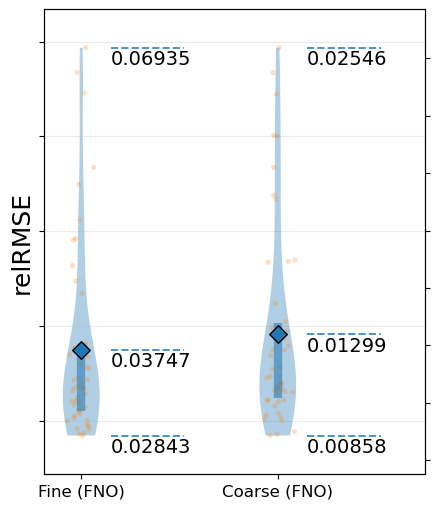

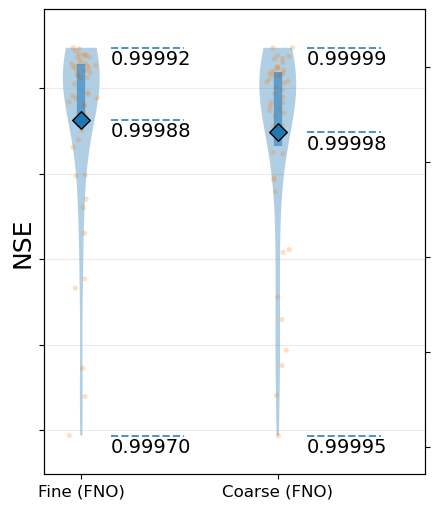

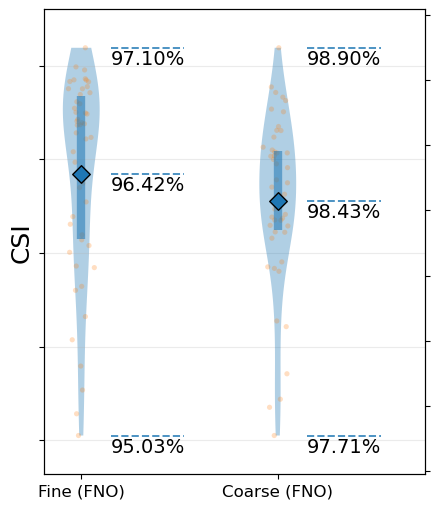

(<Figure size 450x520 with 2 Axes>, <Axes: ylabel='CSI'>)

In [20]:
coarse_metrics_viol = eventwise_relrmse_nse_for_violin(
    u_true_all_coarse,
    u_pred_coarse_all
)


coarse_csi_viol = eventwise_csi_for_violin(
    u_true_all_coarse,
    u_pred_coarse_all
)



fine_metrics_viol = eventwise_relrmse_nse_for_violin(
    u_true_all,
    u_upscaled_final
)


fine_csi_viol = eventwise_csi_for_violin(
    u_true_all,
    u_upscaled_final
)



plot_test_violin_D(
    fine_metrics_viol["relRMSE"],
    coarse_metrics_viol["relRMSE"],
    metric_label="relRMSE",
    title="Fine and coarse relRMSE across test scenarios",
    ylabel="relRMSE",
    value_format="decimal"
)


plot_test_violin_D(
    fine_metrics_viol["NSE"],
    coarse_metrics_viol["NSE"],
    metric_label="NSE",
    title="Fine and coarse NSE across test scenarios",
    ylabel="NSE"
)


plot_test_violin_D(
    fine_csi_viol["CSI"],
    coarse_csi_viol["CSI"],
    metric_label="CSI",
    title="Fine and coarse CSI across test scenarios",
    ylabel="CSI",
    value_format="percent",
    decimals=2,

)


In [21]:
metrics_coarse = evaluate_flood_metrics(
    Depth_True=u_true_all_coarse,
    Depth_Pred=u_pred_coarse_all,
    peak_percent=0.05
)

metrics_fine = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=u_upscaled_final,
    peak_percent=0.05
)

metrics_fine_inter = evaluate_flood_metrics(
    Depth_True=u_true_all,
    Depth_Pred=torch.Tensor(u_pred_interp),
    peak_percent=0.05
)


# CSI sensitivity vs. wet–dry threshold 

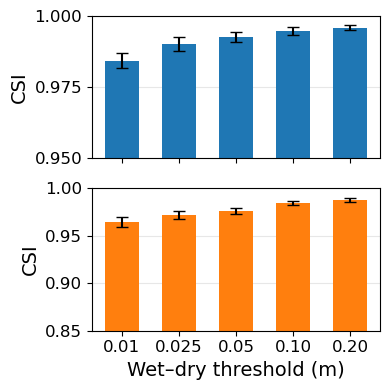

: 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ============================================================
# 1. CONFIGURATION
# ============================================================

threshthresholds = [0.01, 0.025, 0.05, 0.1, 0.2]

eps = 1e-12

# Set to 10 if Fine Magnifier depths are scaled by 10.
# Otherwise, use 1.
fine_threshold_scale = 1

rows = []


# ============================================================
# 2. CSI FUNCTION
# Same formulation as evaluate_flood_metrics()
# Supports PyTorch tensors
# ============================================================

def calculate_csi(
    depth_true,
    depth_pred,
    wet_threshold=0.025,
    eps=1e-12,
):

    # Convert NumPy arrays to tensors if necessary
    if not isinstance(depth_true, torch.Tensor):
        depth_true = torch.as_tensor(depth_true)

    if not isinstance(depth_pred, torch.Tensor):
        depth_pred = torch.as_tensor(
            depth_pred,
            device=depth_true.device,
        )
    else:
        depth_pred = depth_pred.to(depth_true.device)

    # Wet/dry classification
    wet_O_all = depth_true > wet_threshold
    wet_P_all = depth_pred > wet_threshold

    # True positive, false positive, false negative
    TP_all = torch.sum(wet_O_all & wet_P_all).float()
    FP_all = torch.sum(~wet_O_all & wet_P_all).float()
    FN_all = torch.sum(wet_O_all & ~wet_P_all).float()

    # Critical Success Index
    CSI = TP_all / (TP_all + FP_all + FN_all + eps)

    return CSI.item()


# ============================================================
# 3. COARSE FNO CSI VS THRESHOLD
# ============================================================

n_events_coarse = u_true_all_coarse.shape[0]

for thr in thresholds:

    for e in range(n_events_coarse):

        csi = calculate_csi(
            depth_true=u_true_all_coarse[e],
            depth_pred=u_pred_coarse_all[e],
            wet_threshold=thr,
            eps=eps,
        )

        rows.append({
            "Threshold": thr,
            "Model": "Coarse FNO",
            "Event": e,
            "CSI": csi,
        })


# ============================================================
# 4. FINE MAGNIFIER CSI VS THRESHOLD
# ============================================================

n_events_fine = u_true_all.shape[0]

for thr in thresholds:

    fine_thr = fine_threshold_scale * thr

    for e in range(n_events_fine):

        csi = calculate_csi(
            depth_true=u_true_all[e],
            depth_pred=u_upscaled_final[e],
            wet_threshold=fine_thr,
            eps=eps,
        )

        rows.append({
            "Threshold": thr,
            "Model": "Fine Magnifier",
            "Event": e,
            "CSI": csi,
        })


# ============================================================
# 5. CREATE DATAFRAME
# ============================================================

csi_df = pd.DataFrame(rows)


# ============================================================
# 6. SUMMARY: MEAN AND STANDARD DEVIATION
# Same as torch.mean() and torch.std() (unbiased=True)
# ============================================================

summary = (
    csi_df
    .groupby(["Threshold", "Model"], as_index=False)
    .agg(
        CSI_mean=("CSI", "mean"),
        CSI_std=("CSI", lambda x: x.std(ddof=1)),
    )
)


# ============================================================
# 7. PREPARE BAR DATA
# ============================================================

coarse = (
    summary[summary["Model"] == "Coarse FNO"]
    .set_index("Threshold")
    .reindex(thresholds)
)

fine = (
    summary[summary["Model"] == "Fine Magnifier"]
    .set_index("Threshold")
    .reindex(thresholds)
)

x = np.arange(len(thresholds))


# ============================================================
# 7. BAR POSITIONS
# ============================================================

bar_width = 0.5

# Reduce spacing between bars without changing bar width
x = np.arange(len(thresholds)) * 0.85


# ============================================================
# 8. BAR PLOT — TWO VERTICAL PANELS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(4, 4),
    sharex=True,
)


# -----------------------------
# Top panel: Coarse FNO
# -----------------------------
axes[0].bar(
    x,
    coarse["CSI_mean"].to_numpy(),
    width=bar_width,
    yerr=coarse["CSI_std"].to_numpy(),
    capsize=4,
    color="tab:blue",
    label="Coarse FNO",
)

# -----------------------------
# Bottom panel: Fine Magnifier
# -----------------------------
axes[1].bar(
    x,
    fine["CSI_mean"].to_numpy(),
    width=bar_width,
    yerr=fine["CSI_std"].to_numpy(),
    capsize=4,
    color="tab:orange",
    label="Fine Magnifier",
)


# ============================================================
# AXES AND FORMATTING
# ============================================================

# Independent y-axis limits and tick spacing
y_settings = [
    (0.95, 1.00, 0.025),  # Coarse FNO: min, max, spacing
    (0.85, 1.00, 0.05),  # Fine Magnifier: min, max, spacing
]

for ax, (ymin, ymax, ystep) in zip(axes, y_settings):

    ax.set_ylabel(
        "CSI",
        fontsize=14,
    )

    ax.set_xticks(x)

    ax.set_ylim(ymin, ymax)
    ax.set_yticks(np.arange(ymin, ymax + ystep / 2, ystep))

    ax.tick_params(
        axis="y",
        labelsize=12,
    )

    ax.grid(
        True,
        axis="y",
        alpha=0.3,
    )

    ax.set_axisbelow(True)

# -----------------------------
# Bottom panel x-axis
# -----------------------------
axes[1].set_xlabel(
    "Wet–dry threshold (m)",
    fontsize=14,
)

axes[1].set_xticklabels(
    ["0.01", "0.025", "0.05", "0.10", "0.20"],
    fontsize=12,
)

plt.tight_layout()

plt.show()

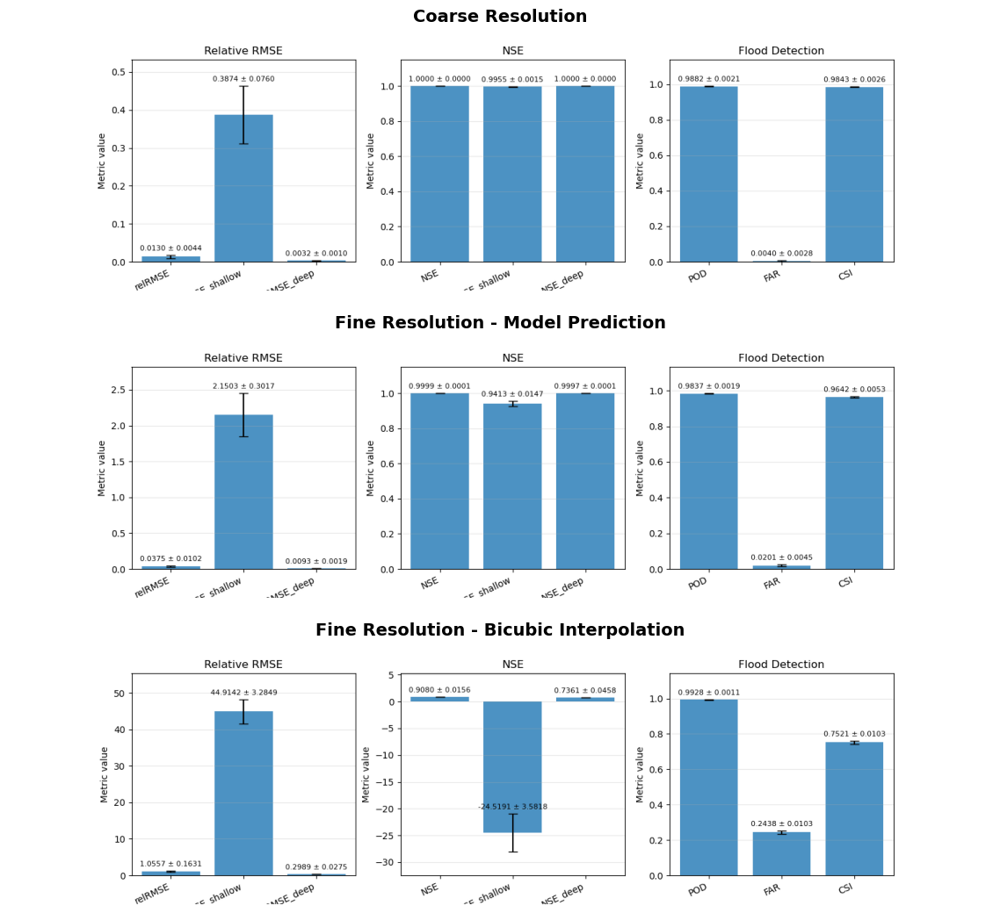

In [22]:
# ============================================================
# VERTICALLY STACKED STATIC METRICS PLOTS
# Coarse / Fine Resolution / Fine Interpolation
# ============================================================

# Coarse resolution
fig1, ax1 = plot_metrics(metrics_coarse["static"])

# Fine interpolation baseline
fig2, ax2 = plot_metrics(metrics_fine_inter["static"])

# Fine resolution
fig3, ax3 = plot_metrics(metrics_fine["static"])

# Convert figures to images
def fig_to_array(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba()).copy()

img1 = fig_to_array(fig1)
img2 = fig_to_array(fig2)
img3 = fig_to_array(fig3)

plt.close(fig1)
plt.close(fig2)
plt.close(fig3)

# Combined figure (3 rows, 1 column)
fig, axes = plt.subplots(3, 1, figsize=(12, 10.5))

axes[0].imshow(img1)
axes[0].set_title("Coarse Resolution", fontsize=14, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img3)
axes[1].set_title("Fine Resolution - Model Prediction", fontsize=14, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(img2)
axes[2].set_title("Fine Resolution - Bicubic Interpolation", fontsize=14, fontweight="bold")
axes[2].axis("off")

plt.tight_layout(h_pad=2)
plt.show()

# Domain Integrated Hydrograph

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import matplotlib.dates as mdates
from datetime import datetime


import numpy as np
import matplotlib.pyplot as plt
import torch
import matplotlib.ticker as mticker
from datetime import datetime


def plot_domain_integrated_hydrograph_multi_res(
    h_ref, h_coarse, h_fine,
    Lx, Ly,
    idx=0,
    topk_percent=5,
    title=r"Domain-integrated hydrograph $H(t)$",
    show_diff=True,
):
    """
    h_ref:    [nb, nx, ny, nt]
    h_fine:   [nb, nx, ny, nt]
    h_coarse: [nb, mx, my, nt]
    Lx, Ly: physical domain lengths
    """

    def to_float(x):
        if isinstance(x, (tuple, list, np.ndarray)):
            x = np.asarray(x).reshape(-1)[0]
        return float(x)

    Lx = to_float(Lx)
    Ly = to_float(Ly)

    def H_of_t(h, idx_):
        h = np.asarray(h)
        assert h.ndim == 4, "Expected shape [nb, nx, ny, nt]"
        nb, nx, ny, nt_ = h.shape
        assert 0 <= idx_ < nb
        dx = Lx / nx
        dy = Ly / ny
        return (dx * dy) * h[idx_].sum(axis=(0, 1))  # [nt]

    Href = H_of_t(h_ref, idx)
    Hc = H_of_t(h_coarse, idx)
    Hf = H_of_t(h_fine, idx)

    nt = Href.shape[0]

    # ---- Pure 24-hour time axis (00:00 → 24:00) ----
    time_axis = np.linspace(0.0, 24.0, nt)

    # peak window from reference
    k = max(1, int(np.ceil((topk_percent / 100.0) * nt)))
    idx_top = np.argsort(Href)[-k:]
    tmin = time_axis[idx_top].min()
    tmax = time_axis[idx_top].max()

    if show_diff:
        fig, (ax, ax2) = plt.subplots(
            2, 1, figsize=(6.2,5.2), sharex=True,
            gridspec_kw={"height_ratios": [3, 1]},
            constrained_layout=True

        )
    else:
        fig, ax = plt.subplots(figsize=(6.2, 5.2))
        ax2 = None

    # ---- Main hydrograph ----
    ax.plot(time_axis, Href, label="Reference", lw=2.2, zorder=3, color='black')
    ax.plot(time_axis, Hc, label="Coarse (FNO)", lw=2.0, ls="--", alpha=0.95, zorder=2)
    ax.plot(time_axis, Hf, label="Fine (Magnifier)", lw=2.0, ls="-.", alpha=0.95, zorder=4)

    ax.axvspan(tmin, tmax, alpha=0.3,
               label=f"Ref peak (top {topk_percent}%)",
               zorder=1)

    ax.set_ylabel(r"$H(t)=\int_{\Omega} h\,dA$", fontsize=15)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(frameon=False, ncol=2, fontsize=12, loc='lower center', bbox_to_anchor=(0.6, 0), columnspacing=0.3)
    ax.set_ylim(0, 2.5e8)

    # ---- Difference panel (bar) ----
    if ax2 is not None:

        rel_c = (Hc - Href) / Href * 100
        rel_f = (Hf - Href) / Href * 100

        width = (time_axis[1] - time_axis[0]) * 0.4

        ax2.bar(time_axis - width/2, rel_c,
                width=width, label="Coarse Vs. Reference")

        ax2.bar(time_axis + width/2, rel_f,
                width=width, label="Fine Vs. Reference")

        ax2.axhline(0.0, lw=1.0, alpha=0.4)

        ax2.set_ylabel("Rel. ΔH (%)", fontsize=15)
        ax2.set_ylim(-7, 7)
        ax2.grid(True, alpha=0.3)
        ax2.legend(frameon=False, ncol=2, fontsize=12,
                loc='upper right', bbox_to_anchor=(1, 1.6),
                columnspacing=0.3)

    # ---- Format x-axis as HH:MM ----
    def format_time(x, pos):
        hours = int(x)
        minutes = int(round((x - hours) * 60))
        if minutes == 60:
            hours += 1
            minutes = 0
        return f"    {hours:02d}:{minutes:02d} "

    ax.xaxis.set_major_locator(mticker.MultipleLocator(6))  # every 2 hours
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(format_time))

    if ax2 is not None:
        ax2.xaxis.set_major_locator(mticker.MultipleLocator(4))
        ax2.xaxis.set_major_formatter(mticker.FuncFormatter(format_time))
        ax2.set_xlabel("Time", fontsize=15)
        ax2.tick_params(axis='x', labelrotation=45)

    ax.tick_params(axis="both", labelsize=13)
    if ax2 is not None:
        ax2.tick_params(axis="both", labelsize=13)
    fig.set_size_inches(6.2, 5.2)
    fig.subplots_adjust(left=0.14, right=0.98, top=0.92, bottom=0.20, hspace=0.08)

    return fig, ax


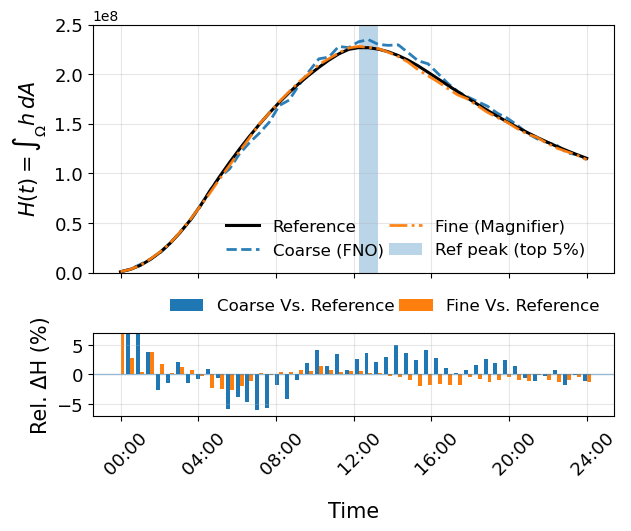

In [ ]:
Lx=checkpoint_mag['config_arg']['data_mask']['L_x']
Ly=checkpoint_mag['config_arg']['data_mask']['L_y']

fig, _ = plot_domain_integrated_hydrograph_multi_res(
    h_ref=u_true_all, 
    h_coarse=u_pred_coarse_all, 
    h_fine=  u_upscaled_final,
    Lx=Lx, Ly=Ly,
    idx=0,
    topk_percent=5,
    title=None,
)



# Flood Detection skill over time

In [27]:
def plot_detection_skill_time_multi(
    dynamic_metrics_list,
    model_names,
    start_time=0.0,     # hours, e.g. 0.0 for 00:00
    end_time=24.0,      # hours, e.g. 24.0 for 24:00
    figsize=(8, 6),
    linewidth=2,
    far_alpha=0.5,
    legend_models_loc="upper left",
    legend_models_bbox=(0.01, 0.85),
    legend_metrics_loc="upper right",   # kept for compatibility, not used
    legend_metrics_bbox=(0.99, 0.85),   # kept for compatibility, not used
    legend_fontsize=14,
    legend_models_ncol=1,
):
    """
    Panel 1: POD (%) on standard axis.
    Panel 2: CSI (%) on standard axis.
    Panel 3: FAR (%) on standard axis.

    X-axis:
        Time-of-day from start_time to end_time in hours,
        displayed as HH:MM.

    This avoids the inverted CSI axis while keeping POD, CSI, and FAR visually separated.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.ticker import FuncFormatter, MultipleLocator

    if len(dynamic_metrics_list) != len(model_names):
        raise ValueError("dynamic_metrics_list and model_names must match length")

    def to_numpy(x):
        if hasattr(x, "detach"):
            return x.detach().cpu().numpy()
        return np.asarray(x)

    nt = len(to_numpy(dynamic_metrics_list[0]["CSI_t"]))

    # --- TIME AXIS in hours ---
    time_axis = np.linspace(float(start_time), float(end_time), nt)

    fig, (ax_pod, ax_csi, ax_far) = plt.subplots(
        3, 1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"height_ratios": [1, 1, 1]}
    )

    colors = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])
    if not colors:
        colors = [None] * len(model_names)

    model_handles = []

    # ============================
    # POD PANEL
    # ============================
    for i, (metrics, name) in enumerate(zip(dynamic_metrics_list, model_names)):
        c = colors[i % len(colors)]
        POD = to_numpy(metrics["POD_t"]) * 100

        h_model = ax_pod.plot(
            time_axis, POD,
            "-",
            linewidth=linewidth,
            color=c,
            label=name
        )[0]

        model_handles.append(h_model)

    ax_pod.set_ylabel("POD (%)", fontsize=15)
    ax_pod.set_ylim(80, 105)
    ax_pod.set_yticks([80, 90, 100])
    ax_pod.grid(alpha=0.3)

    ax_pod.legend(
        handles=model_handles,
        labels=model_names,
        loc=legend_models_loc,
        bbox_to_anchor=legend_models_bbox,
        ncol=legend_models_ncol,
        frameon=False,
        fontsize=legend_fontsize,
        title_fontsize=15
    )

    # ============================
    # CSI PANEL
    # ============================
    for i, (metrics, name) in enumerate(zip(dynamic_metrics_list, model_names)):
        c = colors[i % len(colors)]
        CSI = to_numpy(metrics["CSI_t"]) * 100

        ax_csi.plot(
            time_axis, CSI,
            "-",
            linewidth=linewidth,
            color=c,
            label=name
        )

    ax_csi.set_ylabel("CSI (%)", fontsize=15)
    ax_csi.set_ylim(50, 105)
    ax_csi.set_yticks([50, 75, 100])
    ax_csi.grid(alpha=0.3)

    # ============================
    # FAR PANEL
    # ============================
    for i, (metrics, name) in enumerate(zip(dynamic_metrics_list, model_names)):
        c = colors[i % len(colors)]
        FAR = to_numpy(metrics["FAR_t"]) * 100

        ax_far.fill_between(
            time_axis, 0, FAR,
            alpha=far_alpha,
            color=c,
            label=name
        )

        ax_far.plot(
            time_axis, FAR,
            "-",
            linewidth=linewidth,
            color=c
        )

    ax_far.set_ylabel("FAR (%)", fontsize=15)
    ax_far.set_ylim(0, 50)
    ax_far.set_yticks([0, 25, 50])
    ax_far.grid(alpha=0.5)

    # --- Format x-axis as HH:MM ---
    def hours_to_hhmm(x, pos=None):
        total_minutes = int(round(x * 60))
        h = total_minutes // 60
        m = total_minutes % 60
        return f"{h:02d}:{m:02d}"

    ax_far.xaxis.set_major_formatter(FuncFormatter(hours_to_hhmm))
    ax_far.xaxis.set_major_locator(MultipleLocator(4))
    ax_far.xaxis.set_minor_locator(MultipleLocator(1))
    ax_far.set_xlabel("Time", fontsize=15)

    # Tick label sizes
    ax_pod.tick_params(axis="both", labelsize=13)
    ax_csi.tick_params(axis="both", labelsize=13)
    ax_far.tick_params(axis="both", labelsize=13)

    plt.tight_layout()

    return fig, (ax_pod, ax_csi, ax_far)

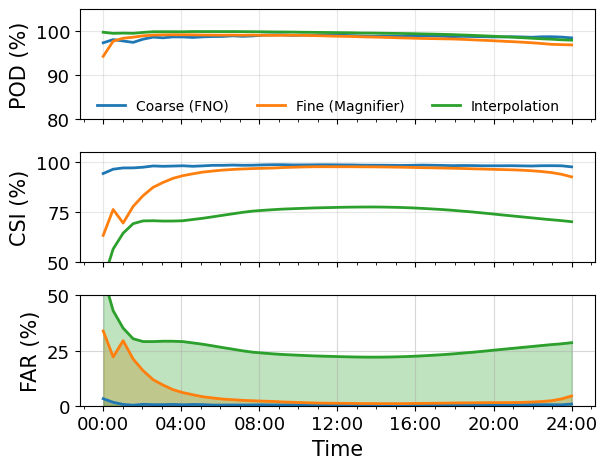

In [28]:
fig, ax = plot_detection_skill_time_multi(
    dynamic_metrics_list=[
        metrics_coarse["dynamic"],
        metrics_fine["dynamic"],
        metrics_fine_inter["dynamic"]
    ],
    legend_fontsize=10,
    figsize=(6.2, 4.8),
    far_alpha=0.3,
    legend_models_ncol=3,
    legend_models_bbox=(0.01, 0.3),

    model_names=["Coarse (FNO)", "Fine (Magnifier)", "Interpolation"])


# Inundation Extent Dynamics

In [30]:
def plot_inundation_extent_time_multi(
    extent_true,
    extent_pred_list,
    model_names,
    idx,
    start_time=0.0,     # hours (e.g., 0.0)
    end_time=24.0,      # hours (e.g., 24.0)
    figsize=(8, 6),
    legend_models_loc="upper left",
    legend_models_bbox=(0.01, 0.8),
    legend_metrics_loc="upper right",
    legend_metrics_bbox=(0.99, 1.20),
    legend_models_ncol=2,
    linewidth=2,
    legend_fontsize=12
):
    """
    Top panel: Inundation extent (km^2)
    Bottom panel: Absolute relative error (%)

    X-axis:
        Time-of-day (hours 0–24), ticks every 4 hours.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter, MultipleLocator

    if len(extent_pred_list) != len(model_names):
        raise ValueError("extent_pred_list and model_names must have same length")

    def to_numpy(x):
        if hasattr(x, "detach"):
            return x.detach().cpu().numpy()
        return np.asarray(x)

    true = to_numpy(extent_true)[idx] / 1e6  # km²
    nt = len(true)

    # ---- TIME AXIS (no dates) ----
    time_axis = np.linspace(float(start_time), float(end_time), nt)

    fig, (ax_top, ax_bottom) = plt.subplots(
        2, 1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"height_ratios": [2, 1]}
    )

    colors = plt.rcParams["axes.prop_cycle"].by_key().get("color", [])

    # =========================
    # TOP PANEL — EXTENT
    # =========================
    h_ref = ax_top.plot(
        time_axis, true, "-",
        color="black", linewidth=linewidth
    )[0]

    model_handles = [h_ref]
    model_labels = ["Reference"]

    for i, (pred_tensor, name) in enumerate(zip(extent_pred_list, model_names)):
        c = colors[i % len(colors)]
        pred = to_numpy(pred_tensor)[idx] / 1e6

        h_mod = ax_top.plot(
            time_axis, pred, "-",
            color=c, linewidth=linewidth
        )[0]

        model_handles.append(h_mod)
        model_labels.append(name)

    ax_top.set_ylabel("Inundation Extent (km$^2$)", fontsize=15)
    ax_top.grid(alpha=0.3)

    # =========================
    # BOTTOM PANEL — ERROR
    # =========================
    for i, (pred_tensor, name) in enumerate(zip(extent_pred_list, model_names)):
        c = colors[i % len(colors)]
        pred = to_numpy(pred_tensor)[idx] / 1e6
        rel_err = np.abs(pred - true) / (true + 1e-8) * 100.0

        ax_bottom.plot(
            time_axis, rel_err, "--",
            color=c, linewidth=linewidth,
            label=name
        )

    ax_bottom.set_ylabel("Absolute\nRel. Error (%)", fontsize=15)
    ax_bottom.set_ylim(bottom=0)
    ax_bottom.grid(alpha=0.3)
    ax_bottom.legend(
        frameon=False,
        loc=legend_metrics_loc,
        ncol=3,
        fontsize=legend_fontsize,
        columnspacing=0.3
    )

    # =========================
    # Time formatting (HH:MM)
    # =========================
    def hours_to_hhmm(x, pos=None):
        total_minutes = int(round(x * 60))
        h = total_minutes // 60
        m = total_minutes % 60
        return f"{h:02d}:{m:02d}"

    ax_bottom.set_xlabel("Time", fontsize=15)
    ax_bottom.xaxis.set_major_formatter(FuncFormatter(hours_to_hhmm))

    # ---- Every 4 hours ----
    ax_bottom.xaxis.set_major_locator(MultipleLocator(4))
    ax_bottom.xaxis.set_minor_locator(MultipleLocator(1))

    # =========================
    # Dual legend (top only)
    # =========================
    leg1 = ax_top.legend(
        handles=model_handles,
        labels=model_labels,
        loc=legend_models_loc,
        bbox_to_anchor=legend_models_bbox,
        ncol=2,
        frameon=False,
        columnspacing=0.3,
        fontsize=legend_fontsize
    )
    ax_top.add_artist(leg1)

    # Tick label sizes
    ax_top.tick_params(axis='both', labelsize=13)
    ax_bottom.tick_params(axis='both', labelsize=13)

    metric_handles = [
        Line2D([0], [0], color="k", linestyle="-", linewidth=linewidth, label="Extent"),
        Line2D([0], [0], color="k", linestyle="--", linewidth=linewidth, label="Abs. Rel. Error"),
    ]

    plt.tight_layout()

    return fig, ax_top, ax_bottom

In [ ]:
idx = 0

inundation_extent_refrence = inundation_extent_timeseries(
    depth=u_true_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
)


inundation_extent_coarse_pred = inundation_extent_timeseries(
    depth=u_pred_coarse_all,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
)


inundation_extent_fine_magnifier = inundation_extent_timeseries(
    depth=u_upscaled_final,
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
)




inundation_extent_fine_interp = inundation_extent_timeseries(
    depth=torch.Tensor(u_pred_interp),
    Lx=checkpoint_mag['config_arg']['data_mask']['L_x'],
    Ly=checkpoint_mag['config_arg']['data_mask']['L_y'],
)



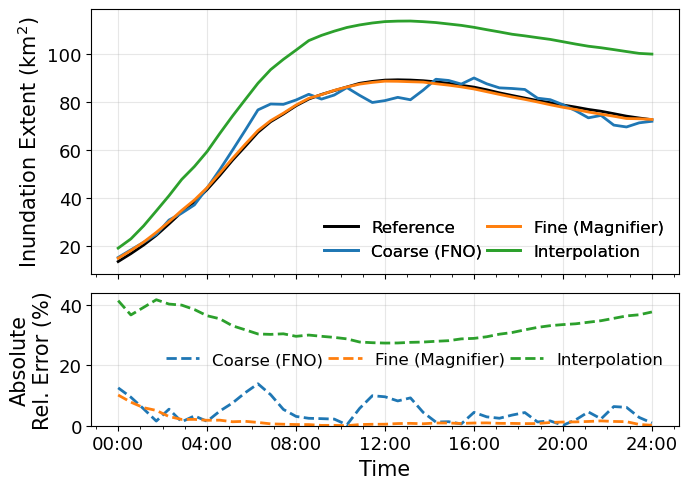

In [ ]:
from datetime import datetime

idx = 20

fig, ax1, ax2 = plot_inundation_extent_time_multi(
    extent_true=inundation_extent_refrence,

    extent_pred_list=[
        inundation_extent_coarse_pred,
        inundation_extent_fine_magnifier,
        inundation_extent_fine_interp
    ],

    model_names=[
        "Coarse (FNO)",
        "Fine (Magnifier)",
        "Interpolation"
    ],

    idx=idx,
    figsize=(7, 5),

    legend_models_loc="lower right",
    legend_models_bbox=None,
    legend_metrics_loc="center right",
    legend_metrics_bbox=None

)
# fig.savefig('../../../paper/figs/inundation_extent_timeseries_dam_break.pdf', dpi=600, bbox_inches='tight')


# INUNDATION CONFUSION PLOTS

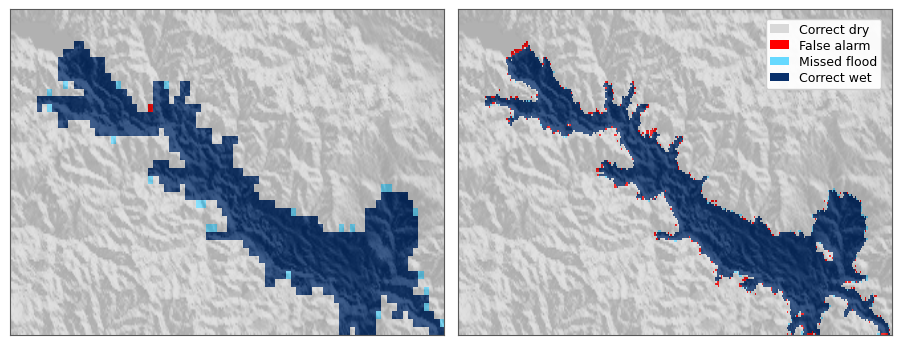

In [ ]:
from lib.evaluation import plot_inundation_confusion_multi_res

fig, axes = plot_inundation_confusion_multi_res(
    u_true_all_coarse=u_true_all_coarse,
    u_pred_coarse_all=u_pred_coarse_all,
    u_true_all=u_true_all,
    u_upscaled_final=u_upscaled_final,
    bed_topo_all=bed_topo_all,
    sample_idx_coarse=20,
    sample_idx_fine=1,
    inund_th=0.01,
    figsize=(9, 6.5),
)

# Scatter plot

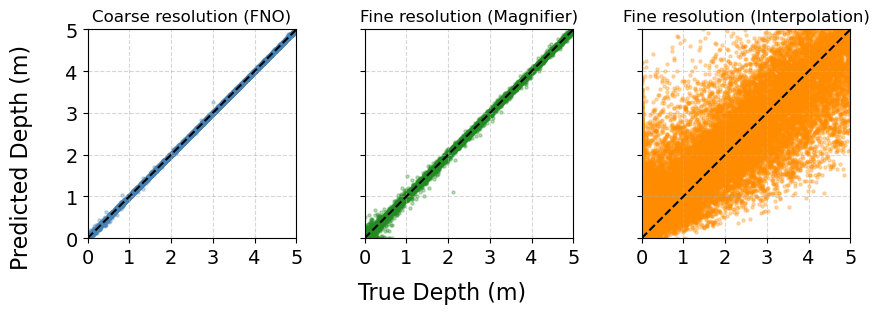

In [19]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ─── Data Setup ─────────────────────────────────────────────────────────────

# Coarse
u_true_c = u_true_all_coarse.detach().cpu().numpy()
u_pred_c = u_pred_coarse_all.detach().cpu().numpy()

# Interpolation baseline (Fine)
u_pred_interp = F.interpolate(
    u_pred_coarse_all.permute(0, 3, 1, 2),   # [B, T, mx, my]
    size=(nx_fine, ny_fine),
    mode='bicubic',
    align_corners=False
).permute(0, 2, 3, 1)                         # [B, H, W, T]
u_pred_interp = torch.clamp(u_pred_interp, min=0.0).detach().cpu().numpy()

# Magnifier (Fine)
u_true_f = u_true_all.detach().cpu().numpy()
u_pred_f = u_upscaled_final.detach().cpu().numpy()

# ─── Helper: Collect Scatter Points ─────────────────────────────────────────

def collect_scatter(u_true, u_pred, max_points_per_sample=5000):
    xs, ys = [], []
    for i in range(u_true.shape[0]):
        x = u_true[i].ravel()
        y = u_pred[i].ravel()

        if x.size > max_points_per_sample:
            idx = np.random.choice(x.size, max_points_per_sample, replace=False)
            x = x[idx]
            y = y[idx]

        xs.append(x)
        ys.append(y)

    return np.concatenate(xs), np.concatenate(ys)

# Build scatter sets
x_c, y_c = collect_scatter(u_true_c, u_pred_c)
x_i, y_i = collect_scatter(u_true_f, u_pred_interp)
x_m, y_m = collect_scatter(u_true_f, u_pred_f)

# Shared limits (use fine domain, since it contains the full range)
limit = 5 #max(x_m.max(), y_m.max(), x_i.max(), y_i.max(), x_c.max(), y_c.max())

# ─── Plot: 1 row × 3 cols ───────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharex=True, sharey=True)

panels = [
    (axes[0], x_c, y_c, "Coarse resolution (FNO)", "steelblue"),
    (axes[1], x_m, y_m, "Fine resolution (Magnifier)", "forestgreen"),
    (axes[2], x_i, y_i, "Fine resolution (Interpolation)", "darkorange"),

]


num_ticks = 6  # change if you want more/less ticks
ticks = np.linspace(0, limit, num_ticks)


for ax, x, y, title, color in panels:
    ax.scatter(x, y, s=5, alpha=0.3, color=color, rasterized=True)
    ax.plot([0, limit], [0, limit], 'k--', lw=1.5)
    ax.set_title(title)

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)


    ax.set_aspect('equal', 'box')
    
    # Make y-axis use the same tick locator as x-axis
    ax.yaxis.set_major_locator(ax.xaxis.get_major_locator())

    ax.grid(True, linestyle='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=14)

# Shared labels
fig.supxlabel("True Depth (m)", fontsize=16)
fig.supylabel("Predicted Depth (m)", fontsize=16)

plt.tight_layout()
plt.savefig('../../../paper/figs/scatter_error_dam_break.png', dpi=600, bbox_inches='tight')

plt.show()

# Sample flood depth prediction

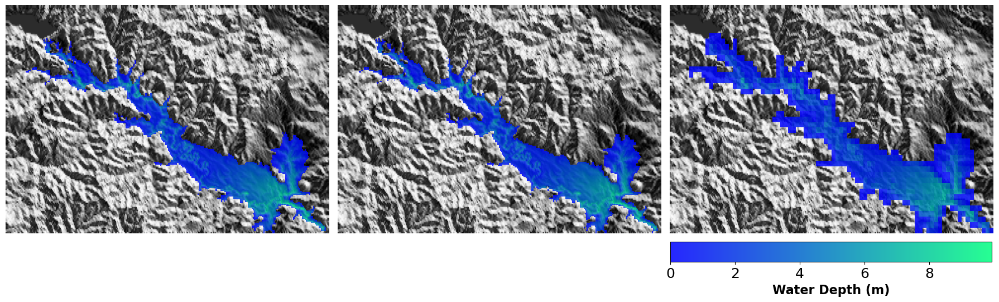

Time: 17:52  |  Frame: 35/47


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from datetime import datetime, timedelta

# ---------------------------
# USER CHOICES
# ---------------------------
sample_idx = 20
time_step  = 35  # <-- frame index you want (0 ... num_frames-1)
extent = [0, 46890.0/1000, 0, 23600.0/1000]

# ---------------------------
# TIME RANGE (NO DATE)
# start = 00:00 , end = 24:00
# ---------------------------
start_seconds = 0               # 00:00
end_seconds   = 24 * 3600       # 24:00

# ==========================================
# 4) Hillshade bed background
# ==========================================
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# ==========================================
# Data
# ==========================================
u_true_c = u_true_all_coarse[sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[sample_idx].detach().cpu().numpy()

u_true_f = u_true_all[sample_idx].detach().cpu().numpy()
u_pred_f = u_upscaled_final[sample_idx].detach().cpu().numpy()

num_frames = u_true_f.shape[-1]

# ==========================================
# Time vector: 00:00 -> 24:00 (no dates)
# ==========================================
time_step = int(np.clip(time_step, 0, num_frames - 1))

total_seconds = (end_seconds - start_seconds)
dt_seconds = total_seconds / (num_frames - 1)

current_seconds = start_seconds + time_step * dt_seconds
hh = int(current_seconds // 3600)
mm = int((current_seconds % 3600) // 60)
time_str = f"{hh:02d}:{mm:02d}"

# --- Match your reference styling ---
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

global_max_depth = 0.8 * max(u_true_f.max(), u_pred_f.max())
vmin, vmax = 0.0, global_max_depth

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# Hillshade
# ==========================================
Z = bed_sample
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(Z, vert_exag=2.5, dx=dx, dy=dy)

# ==========================================
# Static Figure: 1 Row x 3 Cols
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# ---- Data at selected time ----
coarse_pred = u_pred_c[:, :, time_step]
fine_true   = u_true_f[:, :, time_step]
fine_pred   = u_pred_f[:, :, time_step]

ims = []
for c in range(3):
    ax = axes[c]

    # panel mapping: 0=True fine, 1=pred fine, 2=pred coarse
    if c == 0:
        panel = fine_true
        interp = None
    elif c == 1:
        panel = fine_pred
        interp = None
    else:
        panel = coarse_pred
        interp = "nearest"

    # Bed background
    ax.imshow(
        hill.T, extent=extent, origin="lower",
        cmap=bed_cmap, vmin=0, vmax=1,
        alpha=1.0, zorder=1
    )

    # Water overlay
    im = ax.imshow(
        mask_dry(panel).T, extent=extent, origin="lower",
        cmap=cmp, vmin=vmin, vmax=vmax,
        alpha=0.85, zorder=2,
        interpolation=interp
    )
    ims.append(im)

    ax.set_axis_off()
    ax.set_aspect(1.4)

# --- Horizontal colorbar at bottom ---
cbar_ax = fig.add_axes([0.67, 0.075, 0.32, 0.06])  # [left, bottom, width, height]
cbar = fig.colorbar(ims[-1], cax=cbar_ax, orientation="horizontal")
cbar.set_label("Water Depth (m)", fontsize=16, fontweight='bold')
cbar.ax.tick_params(labelsize=18)

plt.tight_layout()

# Save using ONLY HH_MM (no date)
plt.savefig(f"../../../paper/figs/2d_depth_{time_str.replace(':','_')}_dam_break_V.png",
            dpi=600, bbox_inches='tight')

plt.show()

print(f"Time: {time_str}  |  Frame: {time_step}/{num_frames-1}")


In [34]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation

from datetime import datetime, timedelta
from IPython.display import HTML, display
from matplotlib.colors import LightSource
from matplotlib.ticker import MaxNLocator

# ============================================================
# 1. CONFIGURATION
# ============================================================

sample_idx = 20

start_date = datetime(2016, 10, 5, 12, 0, 0)
end_date = start_date + timedelta(hours=24)

# Animation settings
frame_stride = 4           # 1 = include every time index
fps = 4
figsize = (8 * 2, 5.8 * 2)
dpi = 75

# Plot settings
min_depth_threshold = 0.025
water_cmap = "winter"
bed_cmap = "gist_yarg"

err_vmin, err_vmax = 0.0, 0.2

# Spatial extent
Lx = checkpoint_mag["config_arg"]["data_mask"]["L_x"]
Ly = checkpoint_mag["config_arg"]["data_mask"]["L_y"]

extent = [0, Lx, 0, Ly]

# ============================================================
# 2. DATA SELECTION - ALL TIME INDICES
# ============================================================

n_total = u_true_all.shape[-1]

# Verify temporal dimensions
assert all(
    x.shape[-1] == n_total
    for x in [
        u_true_all_coarse,
        u_pred_coarse_all,
        u_upscaled_final,
    ]
), "Coarse and fine datasets must have matching time dimensions."

# Include all time indices
frame_indices = np.arange(0, n_total, frame_stride)

if frame_indices[-1] != n_total - 1:
    frame_indices = np.append(frame_indices, n_total - 1)

num_frames = len(frame_indices)

# Coarse resolution
u_true_c = (
    u_true_all_coarse[sample_idx]
    .detach()
    .cpu()
    .numpy()[..., frame_indices]
)

u_pred_c = (
    u_pred_coarse_all[sample_idx]
    .detach()
    .cpu()
    .numpy()[..., frame_indices]
)

u_err_c = np.abs(u_true_c - u_pred_c)

# Fine resolution
u_true_f = (
    u_true_all[sample_idx]
    .detach()
    .cpu()
    .numpy()[..., frame_indices]
)

u_pred_f = (
    u_upscaled_final[sample_idx]
    .detach()
    .cpu()
    .numpy()[..., frame_indices]
)

u_err_f = np.abs(u_true_f - u_pred_f)

# ============================================================
# 3. TIMESTAMPS
# ============================================================

# Map all time indices uniformly to the selected 24-hour range
total_seconds = (end_date - start_date).total_seconds()

dt_seconds = total_seconds / max(n_total - 1, 1)

time_dates = [
    start_date + timedelta(seconds=int(i) * dt_seconds)
    for i in frame_indices
]

print(f"Total original time steps: {n_total}")
print(f"Animation frames: {num_frames}")
print(f"First timestamp: {time_dates[0]}")
print(f"Last timestamp: {time_dates[-1]}")

# ============================================================
# 4. BED HILLSHADE
# ============================================================

bed_sample = (
    bed_topo_all[sample_idx]
    .detach()
    .cpu()
    .numpy()
)

valid_shapes = [
    u_true_c.shape[:2],
    u_true_f.shape[:2],
]

# Correct bed orientation if necessary
if bed_sample.shape not in valid_shapes:
    if bed_sample.T.shape in valid_shapes:
        bed_sample = bed_sample.T

ls = LightSource(
    azdeg=315,
    altdeg=45,
)

hill = ls.hillshade(
    bed_sample,
    vert_exag=2.5,
    dx=1.0,
    dy=1.0,
)

# ============================================================
# 5. COLOR SCALING
# ============================================================

global_max_depth = 0.8 * max(
    u_true_c.max(),
    u_pred_c.max(),
    u_true_f.max(),
    u_pred_f.max(),
)

vmin = 0.0
vmax = max(float(global_max_depth), 1e-6)


def mask_dry(depth2d):
    return np.ma.masked_where(
        depth2d < min_depth_threshold,
        depth2d,
    )

# ============================================================
# 6. FIGURE: 2 ROWS x 3 COLUMNS
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=figsize,
    dpi=dpi,
    sharex=True,
    sharey=True,
)

titles = [
    [
        "True (Coarse)",
        "Pred (Coarse)",
        "Abs Error (Coarse)",
    ],
    [
        "True (Fine)",
        "Pred (Upscaled)",
        "Abs Error (Fine)",
    ],
]

ims = [[None] * 3 for _ in range(2)]

for r in range(2):

    true_data = u_true_c if r == 0 else u_true_f
    pred_data = u_pred_c if r == 0 else u_pred_f
    err_data = u_err_c if r == 0 else u_err_f

    for c in range(3):

        ax = axes[r, c]

        # Hillshade background
        ax.imshow(
            hill.T,
            extent=extent,
            origin="lower",
            cmap=bed_cmap,
            vmin=0,
            vmax=1,
            zorder=1,
        )

        # Initial frame
        if c == 0:
            frame0 = mask_dry(true_data[:, :, 0])
            cmap = water_cmap
            v0, v1 = vmin, vmax

        elif c == 1:
            frame0 = mask_dry(pred_data[:, :, 0])
            cmap = water_cmap
            v0, v1 = vmin, vmax

        else:
            frame0 = err_data[:, :, 0]
            cmap = "magma"
            v0, v1 = err_vmin, err_vmax

        ims[r][c] = ax.imshow(
            frame0.T,
            extent=extent,
            origin="lower",
            cmap=cmap,
            vmin=v0,
            vmax=v1,
            alpha=0.85 if c < 2 else 0.7,
            interpolation="nearest" if r == 0 else "bilinear",
            zorder=2,
        )

        # Panel title
        ax.set_title(
            titles[r][c],
            fontsize=9,
            fontweight="bold",
            pad=3,
        )

        # Axis formatting
        ax.tick_params(
            axis="both",
            labelsize=7,
            pad=2,
            length=2,
        )

        ax.xaxis.set_major_locator(MaxNLocator(3))
        ax.yaxis.set_major_locator(MaxNLocator(4))

        ax.grid(
            True,
            linestyle="--",
            linewidth=0.4,
            alpha=0.2,
        )

# ============================================================
# 7. TIGHT LAYOUT AND COLORBARS
# ============================================================

fig.subplots_adjust(
    left=0.055,
    right=0.99,
    top=0.86,
    bottom=0.19,
    wspace=0.035,
    hspace=0.12,
)

# Water depth colorbar
cbar_ax1 = fig.add_axes([
    0.14, 0.085, 0.32, 0.015
])

cb1 = fig.colorbar(
    ims[1][0],
    cax=cbar_ax1,
    orientation="horizontal",
)

cb1.set_label(
    "Water Depth (m)",
    fontsize=8,
)

cb1.ax.tick_params(
    labelsize=7,
    length=2,
)

# Absolute error colorbar
cbar_ax2 = fig.add_axes([
    0.59, 0.085, 0.27, 0.015
])

cb2 = fig.colorbar(
    ims[1][2],
    cax=cbar_ax2,
    orientation="horizontal",
)

cb2.set_label(
    "Absolute Error (m)",
    fontsize=8,
)

cb2.ax.tick_params(
    labelsize=7,
    length=2,
)

# ============================================================
# 8. ANIMATION UPDATE
# ============================================================

def update(f_idx):

    current_dt = time_dates[f_idx]

    fig.suptitle(
        f"Flood Refinement Analysis | Sample {sample_idx}\n"
        f"{current_dt:%Y-%m-%d %H:%M}",
        fontsize=11,
        fontweight="bold",
        y=0.98,
    )

    # Coarse resolution
    ims[0][0].set_data(
        mask_dry(u_true_c[:, :, f_idx]).T
    )

    ims[0][1].set_data(
        mask_dry(u_pred_c[:, :, f_idx]).T
    )

    ims[0][2].set_data(
        u_err_c[:, :, f_idx].T
    )

    # Fine resolution
    ims[1][0].set_data(
        mask_dry(u_true_f[:, :, f_idx]).T
    )

    ims[1][1].set_data(
        mask_dry(u_pred_f[:, :, f_idx]).T
    )

    ims[1][2].set_data(
        u_err_f[:, :, f_idx].T
    )

    return [
        im
        for row in ims
        for im in row
    ]

# ============================================================
# 9. GENERATE ANIMATION (NO FFMPEG)
# ============================================================

plt.rcParams["animation.embed_limit"] = 200  # MB

ani = animation.FuncAnimation(
    fig,
    update,
    frames=num_frames,
    interval=1000 / fps,
    blit=False,
    repeat=True,
)

plt.close(fig)

display(
    HTML(
        ani.to_jshtml(
            fps=fps,
            default_mode="loop",
        )
    )
)

Total original time steps: 48
Animation frames: 13
First timestamp: 2016-10-05 12:00:00
Last timestamp: 2016-10-06 12:00:00


Plot inundation confusion

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import LightSource
from IPython.display import HTML
from datetime import datetime, timedelta

# ==========================================
# 1) Data Selection & Error Calculation (Coarse Only)
# ==========================================
sample_idx = 20

u_true_c = u_true_all_coarse[..., ::2][sample_idx].detach().cpu().numpy()
u_pred_c = u_pred_coarse_all[..., ::2][sample_idx].detach().cpu().numpy()
u_err_c  = np.abs(u_true_c - u_pred_c)

num_frames = u_true_c.shape[-1]

# ==========================================
# 2) Time + extent
# ==========================================
start_date = datetime(2016, 10, 5, 12, 0, 0)
time_step_seconds = 3600
time_dates = [start_date + timedelta(seconds=i * time_step_seconds) for i in range(num_frames)]

vmin, vmax = 0.0, 0.8 * u_true_c.max()
err_vmin, err_vmax = 0.0, 0.2

Lx = checkpoint_mag['config_arg']['data_mask']['L_x']
Ly = checkpoint_mag['config_arg']['data_mask']['L_y']
extent = [0, Lx, 0, Ly]

# ==========================================
# 3) Styling like your "first row" example
# ==========================================
min_depth_threshold = 0.025
cmp = "winter"
bed_cmap = "gist_yarg"

def mask_dry(depth2d, thresh=min_depth_threshold):
    return np.ma.masked_where(depth2d < thresh, depth2d)

# ==========================================
# 4) Hillshade bed background (same as first row script)
# ==========================================
# Use your bed tensor here (NOT water). Example: bed_topo_all
bed_sample = bed_topo_all[sample_idx].detach().cpu().numpy()

# ensure bed_sample is [nx, ny] before plotting .T (same convention as water)
# if bed is [ny, nx], transpose it once here
if bed_sample.shape[0] != u_true_c.shape[0] and bed_sample.shape[1] == u_true_c.shape[0]:
    bed_sample = bed_sample.T

# Use physical cell size if you want, but keep it identical style to your example:
dx = 1.0
dy = 1.0
ls = LightSource(azdeg=315, altdeg=45)
hill = ls.hillshade(bed_sample, vert_exag=2.5, dx=dx, dy=dy)  # [0..1]

# ==========================================
# 5) Figure Setup: 1 Row x 3 Columns (first-row look)
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)
titles = ["True (Coarse)", "Pred (Coarse)", "Abs Error (Coarse)"]
ims = [None] * 3
bed_imgs = []

for c, ax in enumerate(axes):
    # 1) Hillshade background (static)
    bed_img = ax.imshow(
        hill.T, extent=extent, origin="lower",
        cmap=bed_cmap, vmin=0, vmax=1,
        alpha=1.0, zorder=1
    )
    bed_imgs.append(bed_img)

    # 2) Foreground layer (dynamic)
    if c == 0:
        ims[c] = ax.imshow(
            mask_dry(u_true_c[:, :, 0]).T, extent=extent, origin="lower",
            cmap=cmp, vmin=vmin, vmax=vmax,
            alpha=0.85, zorder=2
        )
    elif c == 1:
        ims[c] = ax.imshow(
            mask_dry(u_pred_c[:, :, 0]).T, extent=extent, origin="lower",
            cmap=cmp, vmin=vmin, vmax=vmax,
            alpha=0.85, zorder=2
        )
    else:
        ims[c] = ax.imshow(
            u_err_c[:, :, 0].T, extent=extent, origin="lower",
            cmap="magma", vmin=err_vmin, vmax=err_vmax,
            alpha=0.7, zorder=2
        )

    ax.set_title(titles[c], fontsize=14)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.set_xlabel("Easting (m)")

axes[0].set_ylabel("Northing (m)")

# Colorbars
cbar_ax1 = fig.add_axes([0.15, 0.08, 0.35, 0.03])
fig.colorbar(ims[0], cax=cbar_ax1, label="Water Depth (m)", orientation="horizontal")

cbar_ax2 = fig.add_axes([0.65, 0.08, 0.20, 0.03])
fig.colorbar(ims[2], cax=cbar_ax2, label="Abs Error (m)", orientation="horizontal")

plt.subplots_adjust(bottom=0.22, wspace=0.15)

# ==========================================
# 6) Update Function
# ==========================================
def update(f_idx):
    current_dt = time_dates[f_idx]
    fig.suptitle(
        f"Global FNO Dynamics: Sample {sample_idx}\nTime: {current_dt.strftime('%Y-%m-%d %H:%M')}",
        fontsize=16, fontweight="bold"
    )

    ims[0].set_data(mask_dry(u_true_c[:, :, f_idx]).T)
    ims[1].set_data(mask_dry(u_pred_c[:, :, f_idx]).T)
    ims[2].set_data(u_err_c[:, :, f_idx].T)

    return ims

# ==========================================
# 7) Animation
# ==========================================
ani = animation.FuncAnimation(fig, update, frames=range(num_frames), interval=200, blit=False)
plt.close(fig)
HTML(ani.to_jshtml())
